In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

from scipy.stats import f
from sklearn.pipeline import Pipeline
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

In [2]:
class msc(TransformerMixin, BaseEstimator):
    '''
    Custom class implementing MSC as scikit-learn transformer. More info at
    https://nirpyresearch.com/include-msc-custom-pipeline-scikit-learn/
    '''
    def __init__(self, reference=None):
        self.reference = reference
 
    def fit(self, X, y=None):  
        
        X = check_array(X)
        
        # Mean centre correction
        X -=  X.mean(axis=1)[:,np.newaxis]
        
        # If the reference doesn't exist, set it to the average spectrum
        if self.reference is None:
            self.reference =  X.mean(axis=0)
        
        self.is_fitted_ = True
        
        # Fit function must always return self
        return self    
    
    def transform(self, X, y=None):
        check_is_fitted(self)
        
        # Input validation
        X = check_array(X)
        
        # Mean centre correction
        X -=  X.mean(axis=1)[:,np.newaxis]
 
        # MSC Correction
        Xmsc = np.zeros_like(X)
        for i in range(X.shape[0]):
            # Run regression
            fit = np.polyfit(self.reference, X[i,:], 1, full=True)
            # Apply correction
            Xmsc[i,:] = (X[i,:] - fit[0][1]) / fit[0][0]
        
        return Xmsc 

# Load Data
Load and clean the dataset. 
Dataset can be downloaded from here https://data.mendeley.com/datasets/k55b8mvs84/4

In [5]:
fol = '../data/' #Replace with your own data folder
train_raw = pd.read_excel(fol+'Dataset_RAW_Vis-NIR_Spectra_for_Intact_Cucurbitaceae_Fruits.xlsx', sheet_name = 'Calibration Set')
test_raw = pd.read_excel(fol+'Dataset_RAW_Vis-NIR_Spectra_for_Intact_Cucurbitaceae_Fruits.xlsx', sheet_name = 'Prediction Set')

# Rename the first column 
train_raw.rename(columns={'Unnamed: 0': 'veggie_type'}, inplace=True)
test_raw.rename(columns={'Unnamed: 0': 'veggie_type'}, inplace=True)

# Remove the digits from the class names
train_raw['veggie_type'] = train_raw['veggie_type'].str.replace(r'\d+', '', regex=True).str.strip()
test_raw['veggie_type'] = test_raw['veggie_type'].str.replace(r'\d+', '', regex=True).str.strip()

# Extract wavelength
wl = list(train_raw.keys()[3:])

# # Extract spectra
X_train = train_raw[train_raw.keys()[3:]]
X_test = test_raw[test_raw.keys()[3:]]

# Extract classes
veggie_type = train_raw['veggie_type'].unique()

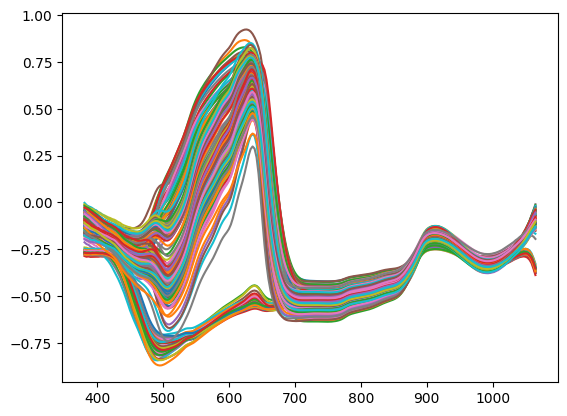

In [6]:
plt.plot(wl, X_train.T)
plt.show()

# LDA
See https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html#sklearn.discriminant_analysis.LinearDiscriminantAnalysis
and
https://nirpyresearch.com/classification-nir-spectra-linear-discriminant-analysis-python/

In [7]:
pipe_lda = Pipeline([('msc', msc()), ('scaler', StandardScaler()), ('lda', LDA(n_components=4) )])
pipe_lda.fit(X_train, train_raw['veggie_type'])
pred = pipe_lda.predict(X_test)

This is how you predict probabilities (rather than binary outcomes) using a trained classifier

In [9]:
pred_prob = pipe_lda.predict_proba(X_test)

Plot confusion matrix on the test set

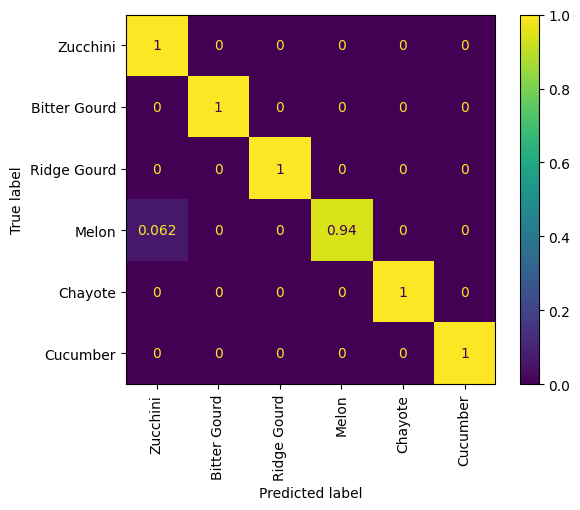

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay
disp = ConfusionMatrixDisplay.from_estimator(
    pipe_lda,
    X_test,
    test_raw['veggie_type'],
    display_labels=veggie_type,
    cmap='viridis',
    normalize='true',
    xticks_rotation='vertical'
)

# SIMCA

In [11]:
# A very basic SIMCA process
ncomp = 5
# set the confidence level
conf = 0.95
models = {} # Empty dict. It will contain the fitted PCA decompositions in each class
for i,j in enumerate(veggie_type):
    models[j] = {}
    # Select the spectra, in the training dataset that belongs to any given class
    X_selected = X_train[train_raw['veggie_type'] == j]

    
    pipe_simca = Pipeline([('msc', msc()), ('scaler', StandardScaler()), ('pca', PCA(n_components=ncomp) )])

    # PCA decomposition on each class
    pipe_simca.fit(X_selected)
    # Save the fitted model into the dictionary
    models[j]['model'] = pipe_simca

    # Calculate preprocessed spectra (before PCA decomposition)
    prep_spectra = pipe_simca['scaler'].transform(pipe_simca['msc'].transform(X_selected))
    # Calculate scores
    T = pipe_simca['pca'].transform(prep_spectra)  
    # Calculate inverse PCA transform
    spectra_inv_tr = pipe_simca['pca'].inverse_transform(T)    
    
    # Calculate Q-residuals
    E = prep_spectra - spectra_inv_tr  
    Q = np.sum(E**2, axis=1)

    # Estimate the confidence level for the Q-residuals
    Q_conf = np.percentile(Q, 100*conf)

    # Calculate Hotelling T-squared
    Tsq = np.sum((T/np.std(T, axis=0))**2, axis=1)

    # Calculate confidence level for T-squared from the ppf of the F distribution
    Tsq_conf =  f.ppf(q=conf, dfn=ncomp, \
                dfd=(prep_spectra.shape[0]-ncomp))*ncomp*(prep_spectra.shape[0]-1)/(prep_spectra.shape[0]-ncomp)

    # Add the thresholds values to the models dict
    models[j]['Q'] = Q
    models[j]['Tsq'] = Tsq
    
    # Add the thresholds values to the models dict
    models[j]['Q threshold'] = Q_conf
    models[j]['Tsq threshold'] = Tsq_conf

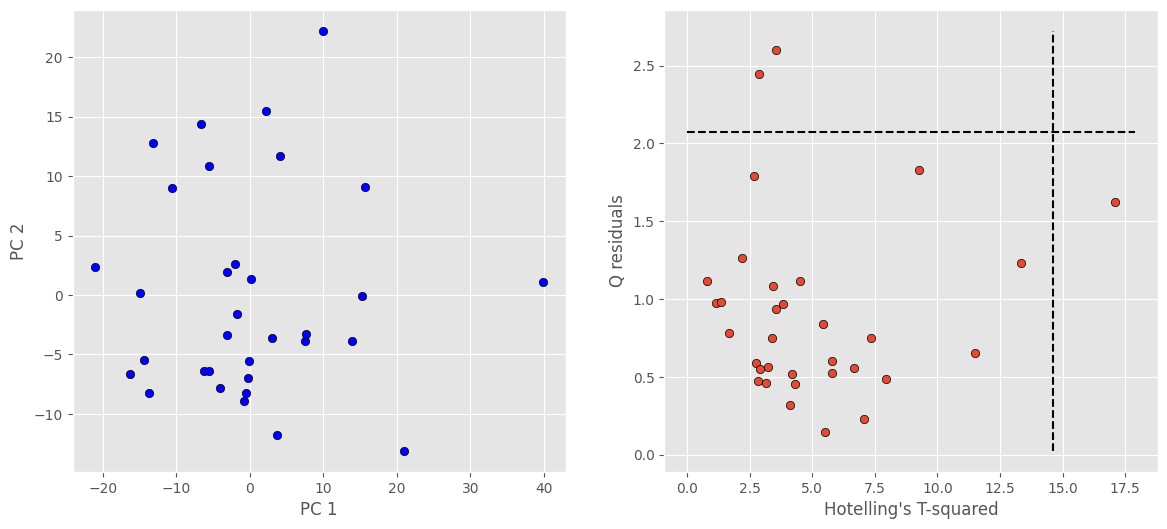

In [12]:
pcas = models['Cucumber']['model'].transform(X_train[train_raw['veggie_type'] == 'Cucumber'])
# ax = plt.figure(figsize=(6,6))
with plt.style.context(('ggplot')):
    fig, axs = plt.subplots(1, 2, figsize=(14, 6))

    axs[0].scatter(pcas[:,0], pcas[:,1], c='blue', ec = 'k')
    axs[0].set_xlabel("PC 1")
    axs[0].set_ylabel('PC 2')
    
    axs[1].scatter(models['Cucumber']['Tsq'], models['Cucumber']['Q'], ec = 'k')
 
    axs[1].plot([models['Cucumber']['Tsq threshold'],models['Cucumber']['Tsq threshold']],[plt.axis()[2],plt.axis()[3]],  'k--')
    axs[1].plot([plt.axis()[0],plt.axis()[1]],[models['Cucumber']['Q threshold'],models['Cucumber']['Q threshold']],  'k--')
    axs[1].set_xlabel("Hotelling's T-squared")
    axs[1].set_ylabel('Q residuals')
 
plt.show()

In [13]:
classification_output = {}
for i,j in enumerate(veggie_type):
    classification_output[j] = {}
    # Select the spectra, in the test dataset that belongs to any given class
    X_selected = X_test[test_raw['veggie_type'] == j]

    # Calculate preprocessed spectra (before PCA decomposition) with the saved model
    prep_spectra = models[j]['model']['scaler'].transform(models[j]['model']['msc'].transform(X_selected))
    # Calculate scores
    T = models[j]['model']['pca'].transform(prep_spectra)  
    # Calculate inverse PCA transform
    spectra_inv_tr = models[j]['model']['pca'].inverse_transform(T)    
    
    # Calculate Q-residuals
    E = prep_spectra - spectra_inv_tr  
    Q = np.sum(E**2, axis=1)

    # Calculate Hotelling T-squared
    Tsq = np.sum((T/np.std(T, axis=0))**2, axis=1)

    # Add the distances to the models dict
    classification_output[j]['Q'] = Q
    classification_output[j]['Tsq'] = Tsq

    # accepted = True if both distances are below the respective thresholds
    accepted = (Q < models[j]['Q threshold']) & (Tsq < models[j]['Tsq threshold'])
    classification_output[j]['accepted'] = accepted


In [44]:
pd.DataFrame(classification_output).T

,Q,Tsq,accepted
Zucchini,"[1.659938474547527, 6.087986144458039, 12.4459...","[8.487545182425409, 2.751559518124662, 3.65351...","[True, False, False, True, True, True, True, T..."
Bitter Gourd,"[9.499180637048084, 2.344407837655674, 7.41963...","[2.832544586206625, 10.002648535086328, 8.2325...","[False, True, False, True, True, True, True, T..."
Ridge Gourd,"[3.6733459479412134, 3.621334643561999, 1.9750...","[5.406015801527191, 3.4124561453653453, 4.9780...","[True, True, True, True, True, False, True, Tr..."
Melon,"[7.294942976876982, 8.611391964741433, 15.7166...","[10.043398726481795, 2.907698198478435, 4.8496...","[True, True, False, True, True, True, True, Fa..."
Chayote,"[1.2913169488372087, 0.7781994054390367, 1.126...","[3.6308005697897476, 8.171656947147888, 4.7860...","[True, True, True, False, True, True, True, Fa..."
Cucumber,"[4.855210522057687, 1.8324334112230423, 1.1300...","[5.236945344016524, 3.957716117361176, 9.75851...","[False, True, True, False, True, False, False,..."
